In [1]:
import pandas as pd
from sqlalchemy import create_engine
import pymysql
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from dotenv import load_dotenv
import os

load_dotenv() # betölti a .env fájlt

db_host = os.getenv("DB_HOST")
db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_name = os.getenv("DB_NAME")

engine = create_engine( f"mysql+pymysql://{db_user}:{db_password}@{db_host}/{db_name}")

query = """
SELECT 
    date,
    temperature_2m,
    relative_humidity_2m,
    dew_point_2m,
    apparent_temperature,
    precipitation_probability,
    precipitation,
    showers,
    rain,
    snowfall,
    snow_depth,
    weather_code,
    pressure_msl,
    surface_pressure,
    cloud_cover,
    cloud_cover_low,
    cloud_cover_mid,
    cloud_cover_high,
    visibility,
    evapotranspiration,
    et0_fao_evapotranspiration,
    vapour_pressure_deficit,
    wind_speed_10m,
    wind_speed_80m,
    wind_speed_120m,
    wind_speed_180m,
    wind_direction_10m,
    wind_direction_80m,
    wind_direction_120m,
    wind_direction_180m,
    wind_gusts_10m,
    temperature_80m,
    temperature_120m,
    temperature_180m,
    soil_temperature_0cm,
    soil_temperature_6cm,
    soil_temperature_18cm,
    soil_temperature_54cm,
    soil_moisture_0_to_1cm,
    soil_moisture_1_to_3cm,
    soil_moisture_3_to_9cm,
    soil_moisture_9_to_27cm,
    soil_moisture_27_to_81cm,
    uv_index,
    uv_index_clear_sky,
    is_day,
    sunshine_duration,
    wet_bulb_temperature_2m,
    total_column_integrated_water_vapour,
    cape,
    lifted_index,
    convective_inhibition,
    freezing_level_height,
    boundary_layer_height,
    shortwave_radiation,
    direct_radiation,
    diffuse_radiation,
    global_tilted_irradiance,
    direct_normal_irradiance,
    terrestrial_radiation,
    shortwave_radiation_instant,
    direct_radiation_instant,
    diffuse_radiation_instant,
    direct_normal_irradiance_instant,
    global_tilted_irradiance_instant,
    terrestrial_radiation_instant
FROM ometeo1h
ORDER BY date
"""

df = pd.read_sql(query, engine, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)


features = [
    "temperature_2m",
    "relative_humidity_2m",
    "dew_point_2m",
    "apparent_temperature",
    "precipitation_probability",
    "precipitation",
    "showers",
    "rain",
    "snowfall",
    "snow_depth",
    "weather_code",
    "pressure_msl",
    "surface_pressure",
    "cloud_cover",
    "cloud_cover_low",
    "cloud_cover_mid",
    "cloud_cover_high",
    "visibility",
    "evapotranspiration",
    "et0_fao_evapotranspiration",
    "vapour_pressure_deficit",
    "wind_speed_10m",
    "wind_speed_80m",
    "wind_speed_120m",
    "wind_speed_180m",
    "wind_direction_10m",
    "wind_direction_80m",
    "wind_direction_120m",
    "wind_direction_180m",
    "wind_gusts_10m",
    "temperature_80m",
    "temperature_120m",
    "temperature_180m",
    "soil_temperature_0cm",
    "soil_temperature_6cm",
    "soil_temperature_18cm",
    "soil_temperature_54cm",
    "soil_moisture_0_to_1cm",
    "soil_moisture_1_to_3cm",
    "soil_moisture_3_to_9cm",
    "soil_moisture_9_to_27cm",
    "soil_moisture_27_to_81cm",
    "uv_index",
    "uv_index_clear_sky",
    "is_day",
    "sunshine_duration",
    "wet_bulb_temperature_2m",
    "total_column_integrated_water_vapour",
    "cape",
    "lifted_index",
    "convective_inhibition",
    "freezing_level_height",
    "boundary_layer_height",
    "shortwave_radiation",
    "direct_radiation",
    "diffuse_radiation",
    "global_tilted_irradiance",
    "direct_normal_irradiance",
    "terrestrial_radiation",
    "shortwave_radiation_instant",
    "direct_radiation_instant",
    "diffuse_radiation_instant",
    "direct_normal_irradiance_instant",
    "global_tilted_irradiance_instant",
    "terrestrial_radiation_instant"
]

target = "temperature_2m"

input_window = 48
output_horizon = 6

scaler = MinMaxScaler()
df[features + [target]] = scaler.fit_transform(df[features + [target]])

df = df.replace([np.inf, -np.inf], np.nan)
df = df.ffill().bfill()



input_window = 48
output_horizon = 6

def create_windowed_dataset(df, features, target, input_window, output_horizon):
    X, y = [], []
    data = df[features + [target]].values
    for i in range(len(data) - input_window - output_horizon):
        X.append(data[i:i+input_window, :len(features)])
        y.append(data[i+input_window:i+input_window+output_horizon, -1])
    return np.array(X), np.array(y)

X, y = create_windowed_dataset(df, features, target, input_window, output_horizon)

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [2]:
#TCN
import tensorflow as tf
from tensorflow.keras import layers, models

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled")
    except RuntimeError as e:
        print(e)


input_shape = (input_window, len(features))

inputs = layers.Input(shape=input_shape)
x = layers.Permute((2, 1))(inputs)  # (batch, features, time)
x = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(x)
x = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(x)
x = layers.GlobalAveragePooling1D()(x)
outputs = layers.Dense(output_horizon)(x)

tcn_model = models.Model(inputs, outputs)
tcn_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history = tcn_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=30,
    batch_size=64
)


2026-02-12 17:17:45.299927: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1770916669.258374  144128 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:10.0, compute capability: 7.5


Epoch 1/30


2026-02-12 17:17:52.156578: I external/local_xla/xla/service/service.cc:163] XLA service 0x72c2e8006980 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-02-12 17:17:52.156616: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
2026-02-12 17:17:52.197337: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-02-12 17:17:52.397270: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900


15/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3043 - mae: 0.4711 

I0000 00:00:1770916673.707525  144216 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1000 - mae: 0.2337 - val_loss: 0.0082 - val_mae: 0.0760
Epoch 2/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0214 - mae: 0.1137 - val_loss: 0.0055 - val_mae: 0.0633
Epoch 3/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0172 - mae: 0.1019 - val_loss: 0.0046 - val_mae: 0.0587
Epoch 4/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0134 - mae: 0.0865 - val_loss: 0.0038 - val_mae: 0.0507
Epoch 5/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0103 - mae: 0.0746 - val_loss: 0.0047 - val_mae: 0.0530
Epoch 6/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0087 - mae: 0.0691 - val_loss: 0.0051 - val_mae: 0.0547
Epoch 7/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0073 - mae: 0.0641 - val_loss: 0.0055 - val_mae: 0.0577
Epoch 8/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0073 - mae: 0.0656 - val_loss: 0.0052 - val_mae: 0.0552
Epoch 9/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0070 - mae: 0.0646 - v

In [3]:
y_pred = tcn_model.predict(X_test)

y_pred_flat = y_pred.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

y_pred_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step


In [4]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_test_real, y_pred_real)
mae = mean_absolute_error(y_test_real, y_pred_real)
rmse = np.sqrt(mse)

print("TCN – MSE:", mse)
print("TCN – MAE:", mae)
print("TCN – RMSE:", rmse)


TCN – MSE: 8.957939430419419
TCN – MAE: 2.2609177000235094
TCN – RMSE: 2.992981695637215


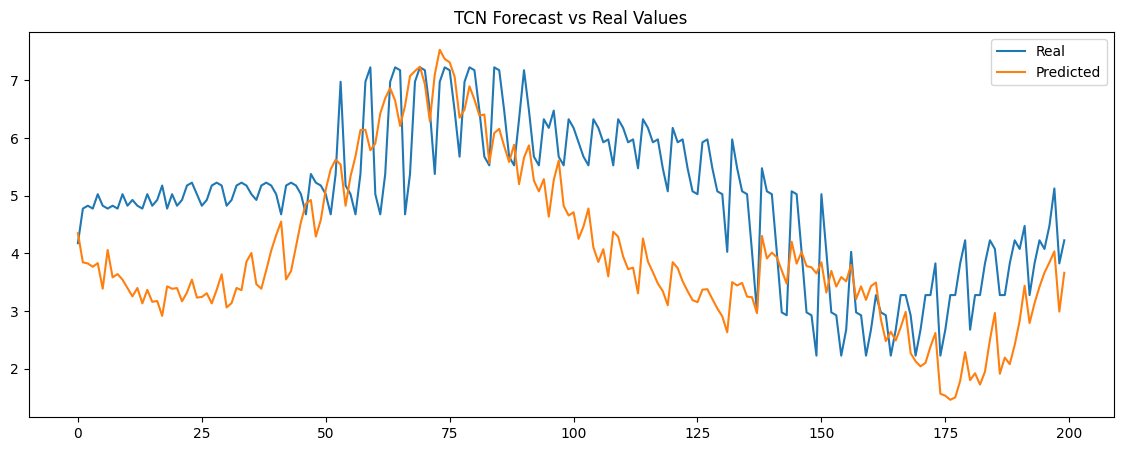

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_real[:200], label="Predicted")
plt.legend()
plt.title("TCN Forecast vs Real Values")
plt.show()


In [6]:
#TFT
from tensorflow.keras.callbacks import EarlyStopping
inputs = layers.Input(shape=input_shape)

# időbeli kódolás (LSTM)
x = layers.LSTM(64, return_sequences=True, dropout=0.2)(inputs)
x = layers.LSTM(64, return_sequences=True, dropout=0.2)(x)

# attention a teljes szekvenciára
attention = layers.MultiHeadAttention(num_heads=4, key_dim=32)
x_attn = attention(x, x)

x = layers.Concatenate()([x, x_attn])
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(output_horizon)(x)

tft_like_model = models.Model(inputs, outputs)
tft_like_model.compile(optimizer="adam", loss="mse", metrics=["mae"])


early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_tft = tft_like_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=64,
    callbacks=[early_stop]
)



Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - loss: 0.0690 - mae: 0.2003 - val_loss: 0.0059 - val_mae: 0.0633
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0268 - mae: 0.1299 - val_loss: 0.0053 - val_mae: 0.0618
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0222 - mae: 0.1194 - val_loss: 0.0056 - val_mae: 0.0643
Epoch 4/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0199 - mae: 0.1124 - val_loss: 0.0040 - val_mae: 0.0517
Epoch 5/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0183 - mae: 0.1079 - val_loss: 0.0047 - val_mae: 0.0575
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0178 - mae: 0.1067 - val_loss: 0.0076 - val_mae: 0.0751
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0160 - mae: 0.1007 - val_loss: 0.0052 - val_mae: 0.0613
Epoch 8/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0157 - mae: 0.0993 - val_loss: 0.0049 - val_mae: 0.0598
Epoch 9/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.014

In [7]:
y_pred_tft = tft_like_model.predict(X_test)

# Flatten (multi-step → 1D)
y_pred_flat = y_pred_tft.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

# Visszaskálázás (csak a target oszlopot)
y_pred_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step


In [8]:
mse_tft = mean_squared_error(y_test_real, y_pred_real)
mae_tft = mean_absolute_error(y_test_real, y_pred_real)
rmse_tft = np.sqrt(mse_tft)

print("TFT-like – MSE:", mse_tft)
print("TFT-like – MAE:", mae_tft)
print("TFT-like – RMSE:", rmse_tft)


TFT-like – MSE: 12.00953206237763
TFT-like – MAE: 2.757369992025895
TFT-like – RMSE: 3.465477176721502


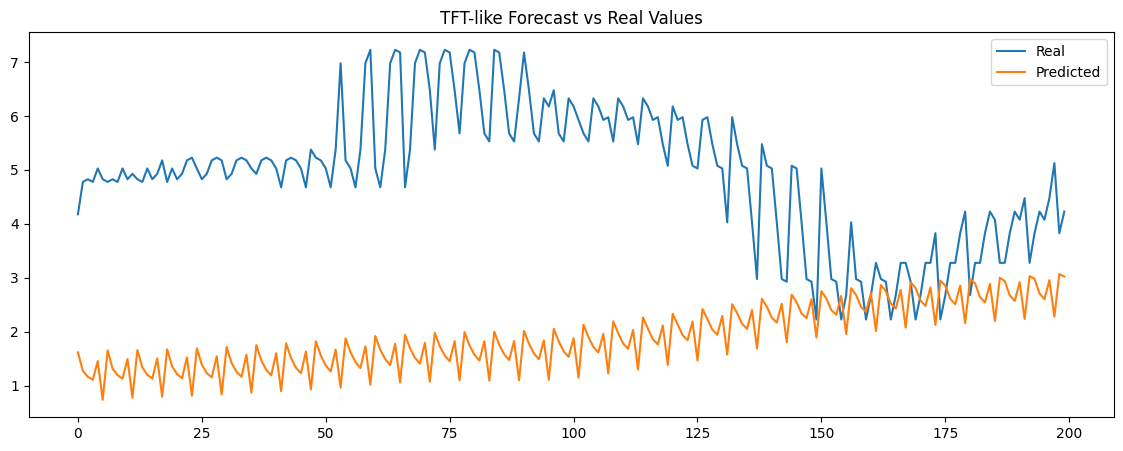

In [9]:

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_real[:200], label="Predicted")
plt.legend()
plt.title("TFT-like Forecast vs Real Values")
plt.show()


In [10]:
#Autoformer
inputs = layers.Input(shape=input_shape)

# lineáris projekció
x = layers.Dense(64)(inputs)

# transformer blokkok
for _ in range(2):
    attn_out = layers.MultiHeadAttention(num_heads=4, key_dim=32)(x, x)
    x = layers.Add()([x, attn_out])
    x = layers.LayerNormalization()(x)
    ff = layers.Dense(128, activation="relu")(x)
    ff = layers.Dense(64)(ff)
    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)

x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(output_horizon)(x)

autoformer_like_model = models.Model(inputs, outputs)
autoformer_like_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history_auto = autoformer_like_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=30,
    batch_size=64
)


Epoch 1/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 99ms/step - loss: 0.0642 - mae: 0.1555 - val_loss: 0.0082 - val_mae: 0.0706
Epoch 2/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0065 - mae: 0.0600 - val_loss: 0.0050 - val_mae: 0.0585
Epoch 3/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0054 - mae: 0.0538 - val_loss: 0.0063 - val_mae: 0.0660
Epoch 4/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0053 - mae: 0.0532 - val_loss: 0.0064 - val_mae: 0.0684
Epoch 5/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0049 - mae: 0.0514 - val_loss: 0.0058 - val_mae: 0.0630
Epoch 6/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0045 - mae: 0.0484 - val_loss: 0.0043 - val_mae: 0.0550
Epoch 7/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0043 - mae: 0.0477 - val_loss: 0.0040 - val_mae: 0.0514
Epoch 8/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0043 - mae: 0.0480 - val_loss: 0.0033 - val_mae: 0.0446
Epoch 9/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0044 

In [11]:
y_pred_auto = autoformer_like_model.predict(X_test)

# Flatten (multi-step → 1D)
y_pred_flat = y_pred_auto.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

# Visszaskálázás (csak a target oszlopot)
y_pred_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step


In [12]:

mse_auto = mean_squared_error(y_test_real, y_pred_real)
mae_auto = mean_absolute_error(y_test_real, y_pred_real)
rmse_auto = np.sqrt(mse_auto)

print("Autoformer-like – MSE:", mse_auto)
print("Autoformer-like – MAE:", mae_auto)
print("Autoformer-like – RMSE:", rmse_auto)


Autoformer-like – MSE: 10.374472789047385
Autoformer-like – MAE: 2.619249767934482
Autoformer-like – RMSE: 3.220942841629976


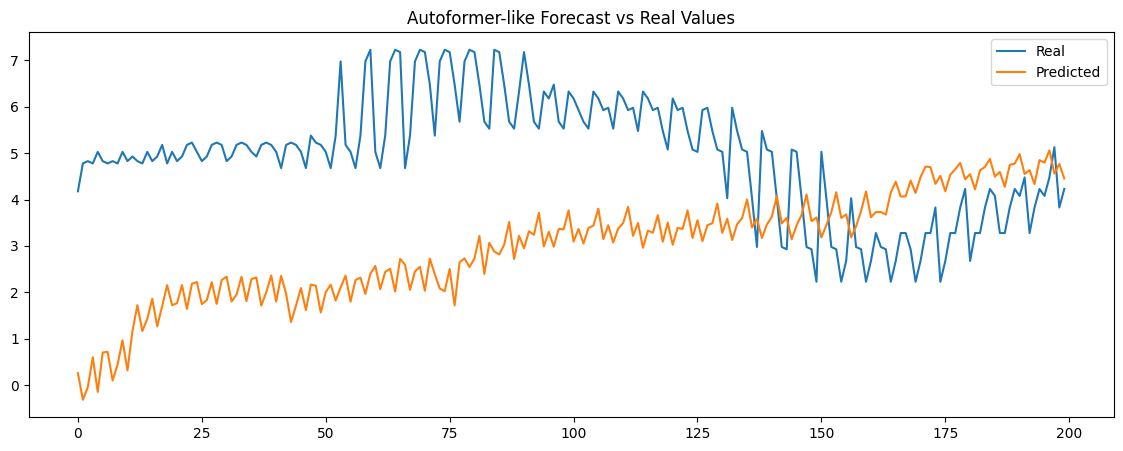

In [13]:

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_real[:200], label="Predicted")
plt.legend()
plt.title("Autoformer-like Forecast vs Real Values")
plt.show()


In [14]:
#TimesNET
inputs = layers.Input(shape=input_shape)

x1 = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(inputs)
x2 = layers.Conv1D(64, kernel_size=5, padding="causal", activation="relu")(inputs)
x3 = layers.Conv1D(64, kernel_size=7, padding="causal", activation="relu")(inputs)

x = layers.Concatenate()([x1, x2, x3])
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(output_horizon)(x)

timesnet_like_model = models.Model(inputs, outputs)
timesnet_like_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history_times = timesnet_like_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=30,
    batch_size=64
)


Epoch 1/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - loss: 0.0289 - mae: 0.1174 - val_loss: 0.0062 - val_mae: 0.0640
Epoch 2/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0072 - mae: 0.0644 - val_loss: 0.0063 - val_mae: 0.0645
Epoch 3/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0058 - mae: 0.0567 - val_loss: 0.0055 - val_mae: 0.0623
Epoch 4/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0052 - mae: 0.0531 - val_loss: 0.0050 - val_mae: 0.0593
Epoch 5/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0046 - mae: 0.0494 - val_loss: 0.0039 - val_mae: 0.0523
Epoch 6/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0042 - mae: 0.0485 - val_loss: 0.0036 - val_mae: 0.0489
Epoch 7/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0036 - mae: 0.0435 - val_loss: 0.0038 - val_mae: 0.0517
Epoch 8/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0032 - mae: 0.0410 - val_loss: 0.0040 - val_mae: 0.0505
Epoch 9/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0031 - mae:

In [15]:
y_pred_times = timesnet_like_model.predict(X_test)

# Flatten (multi-step → 1D)
y_pred_flat = y_pred_times.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

# Visszaskálázás (csak a target oszlopot)
y_pred_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step


In [16]:

mse_times = mean_squared_error(y_test_real, y_pred_real)
mae_times = mean_absolute_error(y_test_real, y_pred_real)
rmse_times = np.sqrt(mse_times)

print("TimesNet-like – MSE:", mse_times)
print("TimesNet-like – MAE:", mae_times)
print("TimesNet-like – RMSE:", rmse_times)


TimesNet-like – MSE: 8.142450735681452
TimesNet-like – MAE: 2.237921416363115
TimesNet-like – RMSE: 2.853497982421129


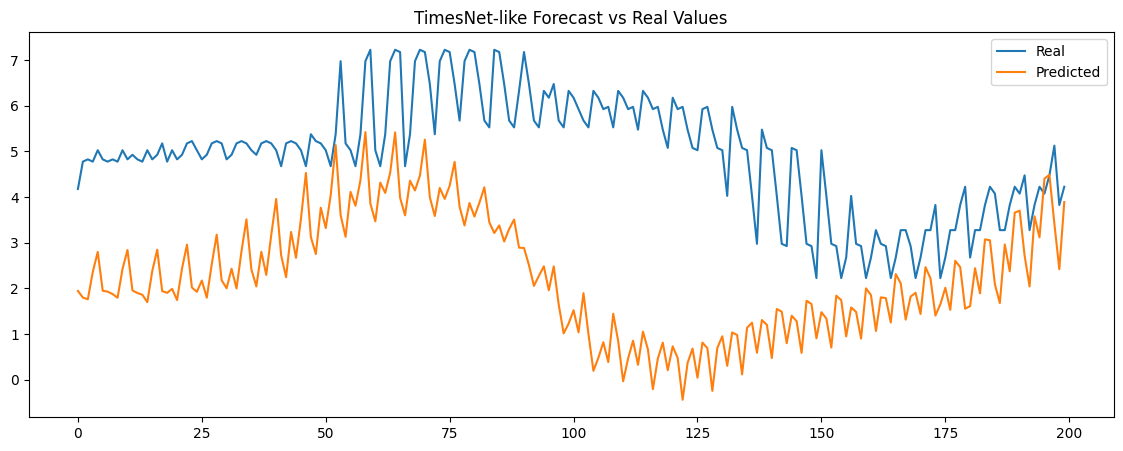

In [17]:

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_real[:200], label="Predicted")
plt.legend()
plt.title("TimesNet-like Forecast vs Real Values")
plt.show()


In [18]:
#Summary
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate_model(model, name):
    y_pred = model.predict(X_test)
    y_pred_flat = y_pred.reshape(-1, 1)
    y_test_flat = y_test.reshape(-1, 1)

    y_pred_real = scaler.inverse_transform(
        np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
    )[:, -1]

    y_test_real = scaler.inverse_transform(
        np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
    )[:, -1]

    mse = mean_squared_error(y_test_real, y_pred_real)
    mae = mean_absolute_error(y_test_real, y_pred_real)
    rmse = np.sqrt(mse)
    print(f"{name} – MSE: {mse:.4f}, MAE: {mae:.4f}, RMSE: {rmse:.4f}")
    return mse, mae, rmse

evaluate_model(tcn_model, "TCN")
evaluate_model(tft_like_model, "TFT-like")
evaluate_model(autoformer_like_model, "Autoformer-like")
evaluate_model(timesnet_like_model, "TimesNet-like")


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
TCN – MSE: 8.9579, MAE: 2.2609, RMSE: 2.9930
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
TFT-like – MSE: 12.0095, MAE: 2.7574, RMSE: 3.4655
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Autoformer-like – MSE: 10.3745, MAE: 2.6192, RMSE: 3.2209
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
TimesNet-like – MSE: 8.1425, MAE: 2.2379, RMSE: 2.8535


(8.142450735681452, 2.237921416363115, np.float64(2.853497982421129))